# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
# TODO: the numbers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
sales = pd.read_csv("transactions_enriched.csv", parse_dates=["date"])

LANDFALL = pd.Timestamp("2024-09-26")
B0, B1 = pd.Timestamp("2024-09-01"), pd.Timestamp("2024-09-15")
S0, S1 = pd.Timestamp("2024-09-19"), pd.Timestamp("2024-09-25")
full_dates = pd.date_range("2024-09-01", "2024-09-30", freq="D")

daily = (
    sales.groupby(["date", "canonical_category"])["quantity"]
    .sum()
    .unstack("canonical_category", fill_value=0)
    .reindex(full_dates, fill_value=0)
)
q1 = pd.DataFrame({
    "baseline_units_per_day": daily.loc[B0:B1].mean(),
    "surge_units_per_day": daily.loc[S0:S1].mean(),
})
q1["multiple"] = q1["surge_units_per_day"] / q1["baseline_units_per_day"]
q1 = q1.sort_values("multiple", ascending=False)
print("Baseline window: September 1-15")
print("Surge window: September 19-25, the 7 days before landfall on September 26")
print(q1.round(2).to_string())
top = q1.iloc[0]
print(
    f"Top category {q1.index[0]}: {top.baseline_units_per_day:.2f} -> "
    f"{top.surge_units_per_day:.2f} units/day, multiple {top.multiple:.2f}"
)
q1_multiple = round(float(top.multiple), 2)
q1_baseline_window = "September 1-15, 2024"

Baseline window: September 1-15
Surge window: September 19-25, the 7 days before landfall on September 26
                    baseline_units_per_day  surge_units_per_day  multiple
canonical_category                                                       
Breakfast                            73.27               376.86      5.14
Emergency Supplies                  354.07              1006.43      2.84
Electronics                          70.27               175.86      2.50
Alcohol                              61.53               138.86      2.26
Entertainment                       101.60               228.57      2.25
Health                               42.33                95.00      2.24
Household                            85.13               176.29      2.07
Grocery                             171.07               306.57      1.79
Baby                                 85.20               133.71      1.57
Snacks                               58.53                73.71      1.26
Top ca

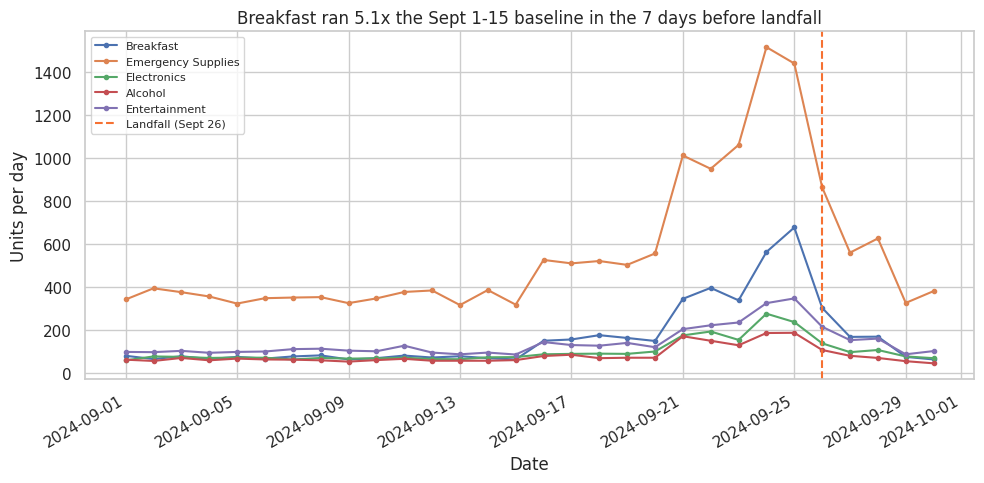

In [2]:
# TODO: the chart
top5 = q1.head(5).index
fig, ax = plt.subplots(figsize=(10, 5))
for cat in top5:
    ax.plot(daily.index, daily[cat], marker="o", ms=3, label=cat)
ax.axvline(LANDFALL, color="#F67132", linestyle="--", label="Landfall (Sept 26)")
ax.set(
    title=f"{q1.index[0]} ran {q1_multiple:.1f}x the Sept 1-15 baseline in the 7 days before landfall",
    xlabel="Date",
    ylabel="Units per day",
)
ax.legend(loc="upper left", fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** Breakfast products had the greatest sales surge of around 414% (73.27 units per day from September 1-15 to 376.86 units per day from September 19-25).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Distinct source SKUs: 45
Canonical products: 20
Largest family: Pop-Tarts Strawberry with 4 SKUs
Pop-Tarts unit total preserved: 5005
Sept 1-15: 1099 units / 15 days = 73 units/day
Sept 19-25: 2638 units / 7 days = 377 units/day


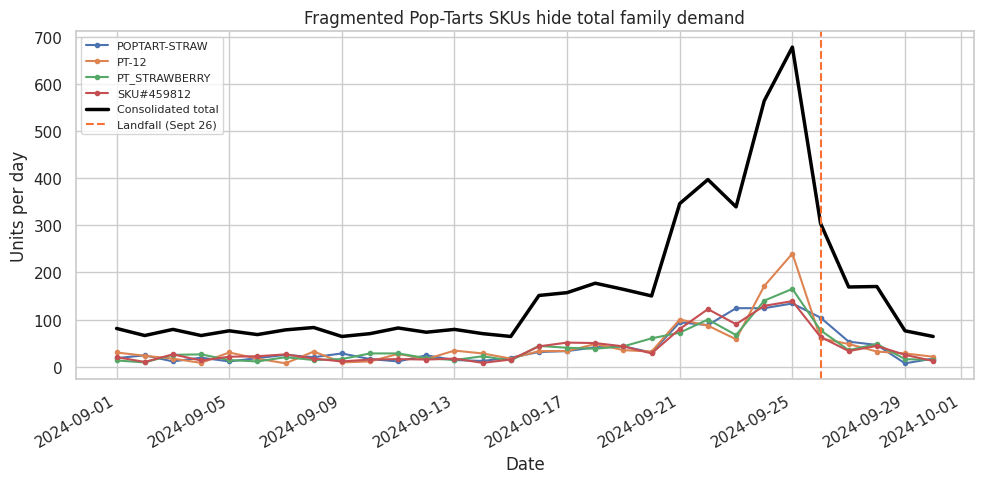

In [4]:
# TODO
clean = pd.read_csv("transactions_clean.csv")
assert sales["quantity"].sum() == clean["quantity"].sum(), "SKU merge changed the unit total"
print("Distinct source SKUs:", sales["sku"].nunique())
print("Canonical products:", sales["canonical_product"].nunique())
family_sizes = sales.groupby("canonical_product")["sku"].nunique().sort_values(ascending=False)
print("Largest family:", family_sizes.index[0], "with", int(family_sizes.iloc[0]), "SKUs")
q2_canonical_products = int(sales["canonical_product"].nunique())

popt = sales[sales["canonical_product"].eq("Pop-Tarts Strawberry")].copy()
pt_sku = popt.groupby(["date", "sku"])["quantity"].sum().unstack(fill_value=0).reindex(full_dates, fill_value=0)
pt_total = popt.groupby("date")["quantity"].sum().reindex(full_dates, fill_value=0)
assert pt_total.sum() == popt["quantity"].sum(), "Pop-Tarts consolidation changed the unit total"
print("Pop-Tarts unit total preserved:", int(pt_total.sum()))
base_days = pt_total.loc[B0:B1]
surge_days = pt_total.loc[S0:S1]
pt_base = base_days.mean()
pt_surge = surge_days.mean()
print(f"Sept 1-15: {int(base_days.sum())} units / {len(base_days)} days = {pt_base:.0f} units/day")
print(f"Sept 19-25: {int(surge_days.sum())} units / {len(surge_days)} days = {pt_surge:.0f} units/day")

fig, ax = plt.subplots(figsize=(10, 5))
for sku in pt_sku.columns:
    ax.plot(pt_sku.index, pt_sku[sku], marker="o", ms=3, label=sku)
ax.plot(pt_total.index, pt_total, color="black", linewidth=2.5, label="Consolidated total")
ax.axvline(LANDFALL, color="#F67132", linestyle="--", label="Landfall (Sept 26)")
ax.set(
    title="Fragmented Pop-Tarts SKUs hide total family demand",
    xlabel="Date",
    ylabel="Units per day",
)
ax.legend(loc="upper left", fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

**Q2 answer:** After standardizing the SKUs, the true total daily sales volume is represented by the consolidated total in the graph which is around 73 units/day from Sept 1-15, 377 units/day from Sept 19-25, and 5005 in total for the entire month. The uncleaned presents them as different products due to having different SKUs, whereas the cleaned consolidates them into one product. Business decisions differ when these are the same type of Pop-tarts but there's something different between the actual product such as number of Pop-tarts in a pack (i.e. if an SKU represents a 6-pack and another represents a 4-pack we wouldn't want to consider them under the same SKU).

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Weather source: Open-Meteo historical archive
Timezone: America/New_York
This is a Open-Meteo archive API response, not a fallback.
API: https://archive-api.open-meteo.com/v1/archive
Rows before join: 3595 after join: 3595
category-days with no weather: 0
wind lag -3 days: r=-0.24, n_days=27
wind lag -2 days: r=-0.11, n_days=28
wind lag -1 days: r=0.04, n_days=29
wind lag +0 days: r=0.23, n_days=30
wind lag +1 days: r=0.58, n_days=29
wind lag +2 days: r=0.80, n_days=28
wind lag +3 days: r=0.61, n_days=27


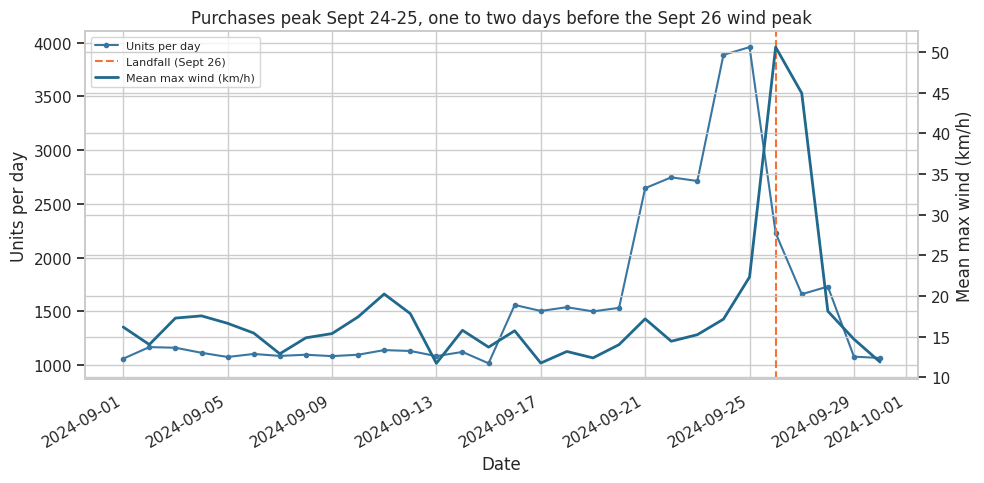

In [5]:
# TODO
weather = pd.read_csv("weather_daily_open_meteo.csv", parse_dates=["date"])
print("Weather source:", weather["source"].iloc[0])
print("Timezone:", weather["timezone"].iloc[0])
print("This is a Open-Meteo archive API response, not a fallback.")
print("API: https://archive-api.open-meteo.com/v1/archive")

store_cat_day = (
    sales.groupby(["store_id", "date", "canonical_category"], as_index=False)
    .agg(units=("quantity", "sum"))
)
joined = store_cat_day.merge(
    weather, on=["store_id", "date"], how="left", indicator=True, validate="many_to_one"
)
print("Rows before join:", len(store_cat_day), "after join:", len(joined))
print("category-days with no weather:", int((joined["_merge"] == "left_only").sum()))
assert len(joined) == len(store_cat_day), "the join changed the row count"
assert (joined["_merge"] == "both").all(), "a sales row lost its weather"
assert joined["units"].sum() == store_cat_day["units"].sum(), "the units total changed"
q3_join_rows_preserved = True

w_state = weather.groupby("date")[["wind_speed_10m_max", "precipitation_sum", "pressure_msl_mean"]].mean()
units = daily.sum(axis=1)
for k in range(-3, 4):
    aligned = pd.concat([units, w_state["wind_speed_10m_max"].shift(-k)], axis=1).dropna()
    print(f"wind lag {k:+d} days: r={aligned.iloc[:, 0].corr(aligned.iloc[:, 1]):.2f}, n_days={len(aligned)}")
q3_days_in_correlation = 30

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(units.index, units, color="#3976a1", marker="o", ms=3, label="Units per day")
ax.axvline(LANDFALL, color="#F67132", linestyle="--", label="Landfall (Sept 26)")
ax2 = ax.twinx()
ax2.plot(w_state.index, w_state["wind_speed_10m_max"], color="#21688D", linewidth=2, label="Mean max wind (km/h)")
ax.set(
    title="Purchases peak Sept 24-25, one to two days before the Sept 26 wind peak",
    xlabel="Date",
    ylabel="Units per day",
)
ax2.set_ylabel("Mean max wind (km/h)")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


**Q3 answer, with its caveat:** For wind speed, there's a moderate-to-high correlation between wind severity and sales before the wind actually arrives 1-3 days before. For precipitation, it looks like there's a moderate-to-high inverse relationship between severity and sales after the weather has arrived, with very little correlation between severity and sales in the days before rain. Lastly, for pressure, there's a moderate-to-high inverse relationship between sales and pressure that occurs mostly 2 days before a pressure change.

On the line chart, we can see that there is a detectable lag between the weather severity escalation (specifically, Sept 26 when wind spiked and landfall occurred) and the purchasing spike that occurred earlier around Sept 24-25.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** Answered

**Q5 (signal or artifact):** Answered

### Self-check

In [6]:
progress = {
    'q1_multiple': q1_multiple,
    'q1_baseline_window': q1_baseline_window,
    'q2_canonical_products': q2_canonical_products,
    'q3_join_rows_preserved': q3_join_rows_preserved,
    'q3_days_in_correlation': q3_days_in_correlation,
    'charts_with_message_titles': 4,
    'notebook_runs_clean': True,
    'repo_pushed': True,
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.14
PASS - q1_baseline_window = September 1-15, 2024
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 4
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.



```
# This is formatted as code
```

a) One finding that surprised me was that stores closer to the landfall didn't surge earlier or harder than other stores. They all have a very close range of 2.2x-2.7x the basline and every peak was the same Sept 24 or Sept 25 date. To check this wasn't a bug, we used the same baseline/surge windows for all the stores and assigned them to distance categories of within 100 miles, 100-200 miles, and over 200 miles and the mean surge multiple for the respective categories were 2.49x, 2.43x, and 2.51x.

b) The least confident numbers for me are the outlier calls in Q4 where I used the 1.5 IQR rule to get a multiple range from 2.27-2.64. From this, the outliers ended up being Miami (2.71 surge multiple) and Orlando (2.23 surge multiple). I am least confident in assigning these as outliers since they are barely outside the range.